# Mini-Proyecto: Asistente Financiero y Bursátil con Model Context Protocol (MCP), LangChain y Ollama

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ohtar10/icesi-nlp/blob/main/mini-proyecto/Mini-Proyecto%20con%20LLM%20y%20Langchain/asistente-financiero-mcp-langchain.ipynb)

**Curso:** Fundamentos de Procesamiento de Lenguaje Natural (NLP) y Modelos Secuenciales  
**Programa:** Maestría Inteligencia Artificial — Universidad ICESI  
**Entregable:** Mini-Proyecto con LLM, LangChain y Model Context Protocol

---

## 1. Planteamiento del Problema y Justificación

Los Modelos de Lenguaje de Gran Escala (LLMs) son extraordinarios procesando lenguaje natural, sintetizando texto y razonando sobre contextos cerrados. Sin embargo, en el dominio financiero y bursátil exhiben dos limitaciones críticas intrínsecas a su arquitectura:

1. **Carencia de *Grounding* Temporal y Acceso en Tiempo Real:** El conocimiento de un LLM está congelado a la fecha de corte de su entrenamiento (*knowledge cutoff*). Un modelo como `llama3.2:3b` no conoce el precio actual de una acción (e.g., Apple, Nvidia o Microsoft) ni la tasa de cambio vigente entre divisas (EUR/USD, USD/COP). Cuando se le interroga sobre precios actuales, el modelo tiende a **alucinar cifras ficticias** con alta convicción.
2. **Incapacidad en Aritmética Precisa y Finanzas Cuantitativas:** Los transformadores operan prediciendo el siguiente token mediante distribuciones de probabilidad sobre representaciones vectoriales, no mediante unidades lógicas aritméticas (ALU). En cálculos financieros deterministas (como proyecciones de interés compuesto con aportes periódicos o cálculo de volatilidad y ratio de Sharpe sobre series históricas), los LLMs cometen errores numéricos sistemáticos inadmisibles en el sector bursátil y de gestión patrimonial.

### ¿Por qué Model Context Protocol (MCP)?

Tradicionalmente, la conexión de LLMs a herramientas externas requería integraciones ad-hoc con formatos propietarios de cada proveedor (*function calling* disperso). El **Model Context Protocol (MCP)**, impulsado como estándar abierto de la industria, desacopla limpiamente las responsabilidades:
- **Servidores MCP independientes:** Exponen capacidades de datos y cómputo determinista a través de contratos estandarizados (JSON-RPC sobre transporte Streamable-HTTP o stdio).
- **Clientes MCP estandarizados:** Descubren dinámicamente las herramientas, recursos y prompts expuestos por los servidores sin acoplamiento duro.
- **Agentes Orquestadores (LangChain / LangGraph):** Permiten al LLM actuar como motor de razonamiento (ReAct) que delega las operaciones sensibles a los servidores MCP especializados.

---

## 2. Pregunta de Investigación e Hipótesis

- **Pregunta de Investigación:**  
  *¿En qué medida la orquestación de herramientas financieras deterministas y de mercado mediante el estándar Model Context Protocol (MCP) reduce las alucinaciones numéricas y mejora la factualidad de un modelo de lenguaje ligero (`llama3.2:3b`) en comparación con un enfoque puramente generativo?*

- **Hipótesis Experimental 1 ($H_1$):**  
  En consultas que involucran precios de mercado en vivo y cálculos financieros compuestos, el LLM puro (sin herramientas) presentará un error factual superior al 80%, mientras que el agente acoplado a servidores MCP alcanzará un 100% de exactitud aritmética y factual verificable.

- **Hipótesis Experimental 2 ($H_2$):**  
  En modelos compactos de 3B parámetros, una estrategia de agente guiado/orquestado con *prompt conditioning* y mecanismos de recuperación (*fallback*) superará al agente puramente autónomo en al menos 20 puntos porcentuales en la tasa de activación exitosa de herramientas (*Tool Call Accuracy*), manteniendo latencias inferiores a 4 segundos por consulta.

---

## 3. Objetivos del Proyecto

1. **Desarrollar dos Servidores FastMCP modulares e independientes:**
   - `MercadoFinancieroMCP`: Consulta cotizaciones bursátiles en tiempo real (acciones, criptomonedas) y tasas de cambio oficiales (Banco Central Europeo).
   - `AnaliticaFinancieraMCP`: Realiza análisis cuantitativo de volatilidad/Sharpe sobre series históricas y proyecciones exactas de interés compuesto.
2. **Realizar un Análisis Exploratorio de Datos (EDA) Financiero:** Explorar series históricas reales de activos representativos, analizando distribuciones de retornos, volatilidad, matrices de correlación y la frontera riesgo-retorno.
3. **Construir el Agente con LangChain y Ollama:** Integrar un cliente `MultiServerMCPClient` que consuma ambos servidores MCP vía HTTP Streamable y construir un agente ReAct con `ChatOllama`.
4. **Diseñar y Ejecutar un Benchmark Experimental Comparativo:** Contrastar tres modos de operación (*Baseline Sin Herramientas*, *Agente Autónomo ReAct* y *Agente Guiado con Fallback*) sobre un banco de 12 consultas categorizadas.
5. **Desplegar una Interfaz de Chat con Gradio:** Proveer una experiencia de usuario interactiva con selección de modos, visualización de trazas MCP en tiempo real y soporte para la demostración en video requerida.


In [1]:
import os
import sys
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')

# Deteccion de entorno de ejecución (Google Colab vs Local)
try:
    import google.colab
    IN_COLAB = True
    print("✅ Entorno detectado: Google Colab")
except ImportError:
    IN_COLAB = False
    print("✅ Entorno detectado: Local")


✅ Entorno detectado: Google Colab


In [2]:
# Verificación y preparación autosuficiente de la estructura de archivos
base_dir = Path.cwd()
servers_dir = base_dir / "mcp_servers"
data_dir = base_dir / "data"

servers_dir.mkdir(parents=True, exist_ok=True)
data_dir.mkdir(parents=True, exist_ok=True)

# Rutas alternativas si se clono el repositorio completo
alt_servers_dir = base_dir / "mini-proyecto" / "Mini-Proyecto con LLM y Langchain" / "mcp_servers"
alt_data_dir = base_dir / "mini-proyecto" / "Mini-Proyecto con LLM y Langchain" / "data"

if alt_servers_dir.exists():
    servers_dir = alt_servers_dir
if alt_data_dir.exists():
    data_dir = alt_data_dir

# 1. Crear __init__.py en mcp_servers si no existe
init_file = servers_dir / "__init__.py"
if not init_file.exists():
    init_file.write_text('"""Servidores MCP para el Asistente Financiero."""\n', encoding="utf-8")

# 2. Servidor de Mercado: market_data_mcp_server.py
market_server_code = servers_dir / "market_data_mcp_server.py"
if not market_server_code.exists():
    market_src = '''from mcp.server.fastmcp import FastMCP
import httpx
import re

mcp = FastMCP("MercadoFinancieroMCP", host="localhost", port=9084)

NAME_TO_TICKER = {
    "apple": "AAPL", "microsoft": "MSFT", "nvidia": "NVDA", "google": "GOOGL",
    "alphabet": "GOOGL", "amazon": "AMZN", "tesla": "TSLA", "meta": "META",
    "facebook": "META", "netflix": "NFLX", "bitcoin": "BTC-USD", "btc": "BTC-USD",
    "ethereum": "ETH-USD", "eth": "ETH-USD"
}

CURRENCY_ALIASES = {
    "dolar": "USD", "dólar": "USD", "usd": "USD", "euro": "EUR", "eur": "EUR",
    "libra": "GBP", "gbp": "GBP", "yen": "JPY", "jpy": "JPY", "franco": "CHF",
    "cad": "CAD", "aud": "AUD", "real": "BRL", "brl": "BRL"
}

def _normalize_ticker(symbol: str) -> str:
    cleaned = symbol.strip().upper()
    lower = symbol.strip().lower()
    if lower in NAME_TO_TICKER:
        return NAME_TO_TICKER[lower]
    cleaned = re.sub(r"[\$\(\)\"\'\s]", "", cleaned)
    return cleaned if cleaned else "AAPL"

def _normalize_currency(curr: str) -> str:
    lower = curr.strip().lower()
    if lower in CURRENCY_ALIASES:
        return CURRENCY_ALIASES[lower]
    cleaned = re.sub(r"[^A-Z]", "", curr.strip().upper())
    return cleaned if len(cleaned) == 3 else "USD"

@mcp.tool()
def consultar_cotizacion(symbol: str) -> str:
    """Consulta la cotizacion en vivo para una accion o criptomoneda (e.g. AAPL, MSFT, NVDA, TSLA, BTC-USD)."""
    ticker = _normalize_ticker(symbol)
    url = f"https://query1.finance.yahoo.com/v8/finance/chart/{ticker}?range=5d&interval=1d"
    headers = {"User-Agent": "Mozilla/5.0"}
    try:
        response = httpx.get(url, headers=headers, timeout=15.0)
        response.raise_for_status()
        data = response.json()
        result = data.get("chart", {}).get("result")
        if not result:
            return f"No se encontro informacion para el activo: '{symbol}' (ticker: {ticker})."
        meta = result[0].get("meta", {})
        price = meta.get("regularMarketPrice")
        currency = meta.get("currency", "USD")
        prev_close = meta.get("previousClose") or meta.get("chartPreviousClose")
        high_day = meta.get("regularMarketDayHigh")
        low_day = meta.get("regularMarketDayLow")

        diff_str = ""
        if prev_close and prev_close > 0 and price:
            chg = price - prev_close
            chg_pct = (chg / prev_close) * 100
            diff_str = f", variacion: {'+' if chg >= 0 else ''}{chg:.2f} {currency} ({'+' if chg >= 0 else ''}{chg_pct:.2f}%)"

        rango_str = f", rango: [{low_day:.2f} - {high_day:.2f}]" if high_day and low_day else ""
        return f"Cotizacion de {ticker}: precio actual {price:.2f} {currency}{diff_str}{rango_str}. (Fuente: Yahoo Finance)."
    except Exception as exc:
        return f"Error consultando cotizacion de {ticker}: {exc}."

@mcp.tool()
def tasa_cambio(from_currency: str, to_currency: str, amount: float = 1.0) -> str:
    """Consulta la tasa de cambio oficial entre divisas (e.g. USD, EUR, GBP, JPY) y convierte un monto."""
    f_curr = _normalize_currency(from_currency)
    t_curr = _normalize_currency(to_currency)
    if f_curr == t_curr:
        return f"Tasa 1:1 entre {f_curr} y {t_curr}. Monto: {amount:.2f} {t_curr}."
    url = f"https://api.frankfurter.dev/v1/latest?base={f_curr}&symbols={t_curr}"
    try:
        r = httpx.get(url, timeout=15.0)
        r.raise_for_status()
        data = r.json()
        rates = data.get("rates", {})
        if t_curr not in rates:
            return f"No se encontro tasa entre {f_curr} y {t_curr}."
        rate = rates[t_curr]
        conv = amount * rate
        date_str = data.get("date", "reciente")
        return f"Tasa oficial ({date_str}): 1 {f_curr} = {rate:.4f} {t_curr}. Para {amount:,.2f} {f_curr}, equivale a {conv:,.2f} {t_curr}. (Fuente: BCE / Frankfurter)."
    except Exception as exc:
        return f"Error consultando divisas {f_curr} a {t_curr}: {exc}."

if __name__ == "__main__":
    mcp.run(transport="streamable-http")
'''
    market_server_code.write_text(market_src, encoding="utf-8")
    print(f"✅ Archivo creado: {market_server_code}")

# 3. Servidor de Analítica: finance_analytics_mcp_server.py
analytics_server_code = servers_dir / "finance_analytics_mcp_server.py"
if not analytics_server_code.exists():
    analytics_src = '''from mcp.server.fastmcp import FastMCP
import httpx
import math
import re

mcp = FastMCP("AnaliticaFinancieraMCP", host="localhost", port=9085)

NAME_TO_TICKER = {
    "apple": "AAPL", "microsoft": "MSFT", "nvidia": "NVDA", "google": "GOOGL",
    "amazon": "AMZN", "tesla": "TSLA", "meta": "META", "bitcoin": "BTC-USD", "btc": "BTC-USD"
}

def _clean_symbol(symbol: str) -> str:
    cleaned = symbol.strip().upper()
    lower = symbol.strip().lower()
    if lower in NAME_TO_TICKER:
        return NAME_TO_TICKER[lower]
    cleaned = re.sub(r"[\$\(\)\"\'\s]", "", cleaned)
    return cleaned if cleaned else "AAPL"

@mcp.tool()
def calcular_rendimiento_y_riesgo(symbol: str, dias: int = 30) -> str:
    """Calcula rendimiento acumulado, volatilidad diaria/anualizada y ratio Sharpe para un activo en dias recientes."""
    ticker = _clean_symbol(symbol)
    dias = max(5, min(int(dias), 365))
    yf_range = "1mo" if dias <= 30 else ("3mo" if dias <= 90 else "1y")
    url = f"https://query1.finance.yahoo.com/v8/finance/chart/{ticker}?range={yf_range}&interval=1d"
    headers = {"User-Agent": "Mozilla/5.0"}
    try:
        response = httpx.get(url, headers=headers, timeout=15.0)
        response.raise_for_status()
        data = response.json()
        result = data.get("chart", {}).get("result")
        if not result:
            return f"No se obtuvieron datos historicos para {ticker}."
        raw_closes = result[0].get("indicators", {}).get("quote", [{}])[0].get("close", [])
        closes = [float(p) for p in raw_closes if p is not None and p > 0]
        if len(closes) < 3:
            return f"Datos insuficientes para {ticker}."
        closes = closes[-dias:]
        p_ini, p_fin = closes[0], closes[-1]
        daily_returns = [(closes[i] - closes[i - 1]) / closes[i - 1] for i in range(1, len(closes))]
        n = len(daily_returns)
        mean_ret = sum(daily_returns) / n
        variance = sum((r - mean_ret) ** 2 for r in daily_returns) / (n - 1) if n > 1 else 0.0
        daily_vol = math.sqrt(variance)
        ann_vol = daily_vol * math.sqrt(252)
        total_return = ((p_fin - p_ini) / p_ini) * 100.0
        ann_return = mean_ret * 252 * 100.0
        sharpe = (ann_return - 4.0) / (ann_vol * 100.0) if ann_vol > 0 else 0.0

        return (
            f"Analisis Cuantitativo de {ticker} ({len(closes)} sesiones / ~{dias} dias):\n"
            f"- Precio inicial: {p_ini:.2f} USD | Precio final: {p_fin:.2f} USD\n"
            f"- Rendimiento acumulado: {total_return:+.2f}%\n"
            f"- Volatilidad diaria: {daily_vol * 100:.2f}% | Volatilidad anualizada: {ann_vol * 100:.2f}%\n"
            f"- Ratio de Sharpe anualizado (Rf=4%): {sharpe:.2f}\n"
            f"Conclusion: {'Tendencia alcista' if total_return > 0 else 'Tendencia bajista'} con riesgo {'alto' if ann_vol * 100 > 30 else 'moderado'}."
        )
    except Exception as exc:
        return f"Error en analitica cuantitativa de {ticker}: {exc}."

@mcp.tool()
def proyeccion_interes_compuesto(capital_inicial: float, tasa_anual_pct: float, anios: int, aporte_mensual: float = 0.0) -> str:
    """Calcula la proyeccion exacta de una inversion a interes compuesto con aportes mensuales."""
    capital_inicial, tasa_anual_pct, anios, aporte_mensual = float(capital_inicial), float(tasa_anual_pct), max(1, int(anios)), float(aporte_mensual)
    r_mensual = (tasa_anual_pct / 100.0) / 12.0
    total_meses = anios * 12
    saldo = capital_inicial
    hitos = {}
    for mes in range(1, total_meses + 1):
        saldo = saldo * (1.0 + r_mensual) + aporte_mensual
        if mes % 12 == 0:
            hitos[mes // 12] = saldo
    total_aportado = capital_inicial + (aporte_mensual * total_meses)
    total_intereses = saldo - total_aportado
    rent_pct = (total_intereses / total_aportado) * 100.0 if total_aportado > 0 else 0.0
    desglose = "\n".join([f"  * Año {a}: {hitos[a]:,.2f} USD" for a in sorted(set([1, max(1, anios // 2), anios])) if a in hitos])

    return (
        f"Proyeccion Interes Compuesto ({anios} años a {tasa_anual_pct:.2f}% anual):\n"
        f"- Capital inicial: {capital_inicial:,.2f} USD | Aporte mensual: {aporte_mensual:,.2f} USD\n"
        f"- Total propio invertido: {total_aportado:,.2f} USD\n"
        f"- Total ganado por intereses: {total_intereses:,.2f} USD\n"
        f"- Saldo final acumulado: {saldo:,.2f} USD (+{rent_pct:.2f}%)\n"
        f"Evolucion:\n{desglose}"
    )

if __name__ == "__main__":
    mcp.run(transport="streamable-http")
'''
    analytics_server_code.write_text(analytics_src, encoding="utf-8")
    print(f"✅ Archivo creado: {analytics_server_code}")

print(f"Directorio de servidores MCP: {servers_dir.resolve()}")
print(f"Directorio de datos (EDA):    {data_dir.resolve()}")


Directorio de servidores MCP: /content/mcp_servers
Directorio de datos (EDA):    /content/data


In [3]:
# Instalacion de dependencias requeridas (solo en Google Colab)
if IN_COLAB:
    !pip install --quiet "mcp>=1.24.0,<2.0.0" "langchain-mcp-adapters>=0.3.0,<0.4.0" \
        langchain langchain-core langchain-ollama langgraph \
        httpx ollama colab-xterm gradio matplotlib seaborn pandas tabulate
    print("✅ Dependencias Python instaladas en Google Colab.")
else:
    print("✅ Entorno local: usando dependencias del entorno actual.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 234.6/234.6 kB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.6/115.6 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.4/80.4 kB 8.6 MB/s eta 0:00:00
✅ Dependencias Python instaladas en Google Colab.


## 4. Instalación y Despliegue de Ollama (`llama3.2:3b`)

Para que el modelo local funcione en **Google Colab**, requerimos:
1. Instalar el ejecutable oficial de **Ollama** en el sistema operativo.
2. Iniciar el servicio `ollama serve` en segundo plano en `http://localhost:11434`.
3. Descargar el modelo `llama3.2:3b`.


In [4]:
# Instalacion del binario de Ollama (en Colab)
if IN_COLAB:
    !sudo apt install zstd -y
    !if ! type ollama > /dev/null; then curl -fsSL https://ollama.com/install.sh | sh; else echo "Ollama ya está instalado."; fi
else:
    print("Entorno local: verifica tener Ollama instalado desde https://ollama.com/")


Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  zstd
0 upgraded, 1 newly installed, 0 to remove and 33 not upgraded.
Need to get 644 kB of archives.
After this operation, 1,845 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble-updates/main amd64 zstd amd64 1.5.5+dfsg2-2build1.1 [644 kB]
Fetched 644 kB in 1s (517 kB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package zstd.
(Reading database ... 127332 files and directo

In [5]:
import subprocess
import time
import httpx

# Iniciar ollama serve en segundo plano y esperar a que responda HTTP 200
def arrancar_servicio_ollama():
    try:
        r = httpx.get("http://localhost:11434/api/tags", timeout=2.0)
        if r.status_code == 200:
            print("✅ El servidor Ollama ya se encuentra activo y respondiendo.")
            return True
    except Exception:
        pass

    print("Iniciando 'ollama serve' en segundo plano...")
    subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

    # Esperar hasta 15 segundos para confirmar conexion
    for seg in range(1, 16):
        time.sleep(1)
        try:
            r = httpx.get("http://localhost:11434/api/tags", timeout=2.0)
            if r.status_code == 200:
                print(f"✅ Servidor Ollama iniciado exitosamente tras {seg}s (http://localhost:11434).")
                return True
        except Exception:
            pass

    print("⚠️ No se pudo verificar el inicio automatico. Si falla, usa una celda con %load_ext colabxterm y arranca 'ollama serve &'.")
    return False

ollama_activo = arrancar_servicio_ollama()


Iniciando 'ollama serve' en segundo plano...
✅ Servidor Ollama iniciado exitosamente tras 2s (http://localhost:11434).


In [6]:
# Descargar el modelo llama3.2:3b en Ollama
MODEL_NAME = "llama3.2:3b"

if IN_COLAB:
    print(f"Descargando modelo '{MODEL_NAME}' en Ollama (esto puede tardar un par de minutos la primera vez)...")
    !ollama pull llama3.2:3b
else:
    print(f"Entorno local: asegurate de tener descargado '{MODEL_NAME}' ejecutando 'ollama pull {MODEL_NAME}'.")


Descargando modelo 'llama3.2:3b' en Ollama (esto puede tardar un par de minutos la primera vez)...



In [7]:
# Verificacion final de conexion y modelos en Ollama
OLLAMA_HOST = os.getenv("OLLAMA_HOST", "http://localhost:11434")

try:
    response = httpx.get(f"{OLLAMA_HOST}/api/tags", timeout=5.0)
    if response.status_code == 200:
        modelos_disponibles = [m["name"] for m in response.json().get("models", [])]
        print(f"✅ Conexion exitosa con Ollama ({OLLAMA_HOST}).")
        print(f"Modelos locales disponibles: {modelos_disponibles}")
        if any(MODEL_NAME in m for m in modelos_disponibles):
            print(f"✅ Modelo '{MODEL_NAME}' listo para experimentacion.")
        else:
            print(f"⚠️ El modelo '{MODEL_NAME}' no aparece en la lista. Ejecuta: !ollama pull {MODEL_NAME}")
    else:
        print(f"⚠️ Ollama respondio con estado {response.status_code}.")
except Exception as exc:
    print(f"⚠️ Aviso: No se pudo conectar con Ollama en {OLLAMA_HOST}: {exc}")
    print("El notebook continuara; las herramientas MCP funcionaran directamente mediante su mecanismo de resiliencia.")


✅ Conexion exitosa con Ollama (http://localhost:11434).
Modelos locales disponibles: ['llama3.2:3b']
✅ Modelo 'llama3.2:3b' listo para experimentacion.


## 5. Implementación y Lanzamiento de los Servidores MCP

Implementamos dos servidores especializados con la librería estándar `FastMCP`:

1. **`MercadoFinancieroMCP` (Puerto 9084):**
   - `consultar_cotizacion(symbol)`: Conecta con Yahoo Finance para consultar cotizaciones en vivo de acciones (AAPL, MSFT, NVDA, TSLA) y criptoactivos (BTC-USD, ETH-USD), retornando precio actual, variación porcentual y rango de la jornada.
   - `tasa_cambio(from_currency, to_currency, amount)`: Consulta la API del Banco Central Europeo (Frankfurter) para obtener tasas de cambio oficiales y conversiones directas entre monedas (EUR, USD, GBP, JPY, CAD, BRL).

2. **`AnaliticaFinancieraMCP` (Puerto 9085):**
   - `calcular_rendimiento_y_riesgo(symbol, dias)`: Descarga el histórico de precios para una ventana de días y calcula de forma determinista el retorno total, volatilidad diaria, volatilidad anualizada y ratio de Sharpe.
   - `proyeccion_interes_compuesto(capital_inicial, tasa_anual_pct, anios, aporte_mensual)`: Evalúa la fórmula de interés compuesto con aportaciones periódicas mes a mes, entregando el capital final acumulado y el total ganado en intereses.


In [8]:
import subprocess
import time
import httpx

PORT_MARKET = 9084
PORT_ANALYTICS = 9085

def is_port_open(port: int) -> bool:
    try:
        r = httpx.get(f"http://localhost:{port}/mcp", timeout=2.0)
        return r.status_code in [200, 400, 404, 405, 406]
    except Exception:
        return False

# Iniciar servidores MCP en segundo plano si no estan activos
if not is_port_open(PORT_MARKET):
    print(f"Iniciando MercadoFinancieroMCP en puerto {PORT_MARKET}...")
    subprocess.Popen([sys.executable, str(market_server_code)], stdout=subprocess.PIPE, stderr=subprocess.PIPE)
else:
    print(f"✅ MercadoFinancieroMCP ya esta activo en puerto {PORT_MARKET}.")

if not is_port_open(PORT_ANALYTICS):
    print(f"Iniciando AnaliticaFinancieraMCP en puerto {PORT_ANALYTICS}...")
    subprocess.Popen([sys.executable, str(analytics_server_code)], stdout=subprocess.PIPE, stderr=subprocess.PIPE)
else:
    print(f"✅ AnaliticaFinancieraMCP ya esta activo en puerto {PORT_ANALYTICS}.")

time.sleep(3)
print(f"Estado servidores MCP:")
print(f"- Mercado   (puerto {PORT_MARKET}): {'DISPONIBLE' if is_port_open(PORT_MARKET) else 'INICIANDO'}")
print(f"- Analitica (puerto {PORT_ANALYTICS}): {'DISPONIBLE' if is_port_open(PORT_ANALYTICS) else 'INICIANDO'}")


Iniciando MercadoFinancieroMCP en puerto 9084...
Iniciando AnaliticaFinancieraMCP en puerto 9085...
Estado servidores MCP:
- Mercado   (puerto 9084): INICIANDO
- Analitica (puerto 9085): INICIANDO


## 6. Análisis Exploratorio de Datos (EDA) del Dominio Financiero

Siguiendo los lineamientos de evaluación del curso, profundizamos en la estructura estadística de las series de tiempo financieras para justificar por qué estas operaciones requieren cómputo determinista y no pueden dejarse a la estimación estocástica del LLM.

Analizamos un conjunto multiactivo que comprende:
- **Acciones Tecnológicas:** Apple (`AAPL`), Microsoft (`MSFT`), Nvidia (`NVDA`), Tesla (`TSLA`).
- **Criptoactivos:** Bitcoin (`BTC-USD`).


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.size'] = 11

csv_path = data_dir / "precios_historicos_muestra.csv"

# Si el CSV no existe, descargarlo dinamicamente desde Yahoo Finance
if not csv_path.exists():
    print("Descargando muestra historica para EDA...")
    tickers_eda = ['AAPL', 'MSFT', 'NVDA', 'TSLA', 'BTC-USD']
    data_dict = {}
    headers = {'User-Agent': 'Mozilla/5.0'}
    for t in tickers_eda:
        try:
            url = f'https://query1.finance.yahoo.com/v8/finance/chart/{t}?range=1y&interval=1d'
            r = httpx.get(url, headers=headers, timeout=15.0)
            if r.status_code == 200:
                res = r.json()['chart']['result'][0]
                ts = res['timestamp']
                cl = res['indicators']['quote'][0]['close']
                dates = [datetime.fromtimestamp(x).strftime('%Y-%m-%d') for x in ts]
                df_t = pd.DataFrame({'Date': dates, t: cl}).dropna().drop_duplicates(subset=['Date']).set_index('Date')
                data_dict[t] = df_t[t]
        except Exception:
            pass
    df_precios = pd.DataFrame(data_dict).dropna()
    df_precios.to_csv(csv_path)
else:
    df_precios = pd.read_csv(csv_path, index_col=0, parse_dates=True)

print(f"Dataset de precios cargado con {df_precios.shape[0]} fechas y {df_precios.shape[1]} activos.")
display(df_precios.head(5))

# Retornos diarios y estadisticas anualizadas
df_retornos = df_precios.pct_change().dropna()

stats_financieras = pd.DataFrame({
    'Precio Final (USD)': df_precios.iloc[-1].round(2),
    'Retorno Total (%)': (((df_precios.iloc[-1] / df_precios.iloc[0]) - 1) * 100).round(2),
    'Retorno Diario Medio (%)': (df_retornos.mean() * 100).round(3),
    'Volatilidad Diaria (%)': (df_retornos.std() * 100).round(2),
    'Volatilidad Anualizada (%)': (df_retornos.std() * np.sqrt(252) * 100).round(2),
    'Ratio Sharpe (Rf=4%)': (((df_retornos.mean() * 252 - 0.04) / (df_retornos.std() * np.sqrt(252)))).round(2),
    'Asimetria': df_retornos.skew().round(2),
    'Curtosis': df_retornos.kurtosis().round(2)
})

print("\nResumen Estadistico Cuantitativo:")
display(stats_financieras)


Dataset de precios cargado con 251 fechas y 5 activos.


,AAPL,MSFT,NVDA,TSLA,BTC-USD
Date,,,,,
2025-10-13,247.660004,514.049988,188.320007,435.899994,113118.664062
2025-10-14,247.770004,513.570007,180.029999,429.239990,110783.164062
2025-10-15,249.339996,513.429993,179.830002,435.149994,108186.039062
2025-10-16,247.449997,511.609985,181.809998,428.750000,106467.789062
2025-10-17,252.289993,513.580017,183.220001,439.309998,107198.265625



Resumen Estadistico Cuantitativo:


,Precio Final (USD),Retorno Total (%),Retorno Diario Medio (%),Volatilidad Diaria (%),Volatilidad Anualizada (%),Ratio Sharpe (Rf=4%),Asimetria,Curtosis
AAPL,340.97,37.68,0.140,1.54,24.49,1.28,-0.49,3.35
MSFT,541.15,5.27,0.042,2.07,32.85,0.20,1.31,13.80
NVDA,226.32,20.18,0.101,2.36,37.46,0.57,0.23,0.66
TSLA,378.03,-13.28,-0.017,2.83,44.89,-0.18,-0.41,2.39
BTC-USD,82737.27,-26.86,-0.089,2.69,42.73,-0.62,-0.14,5.20


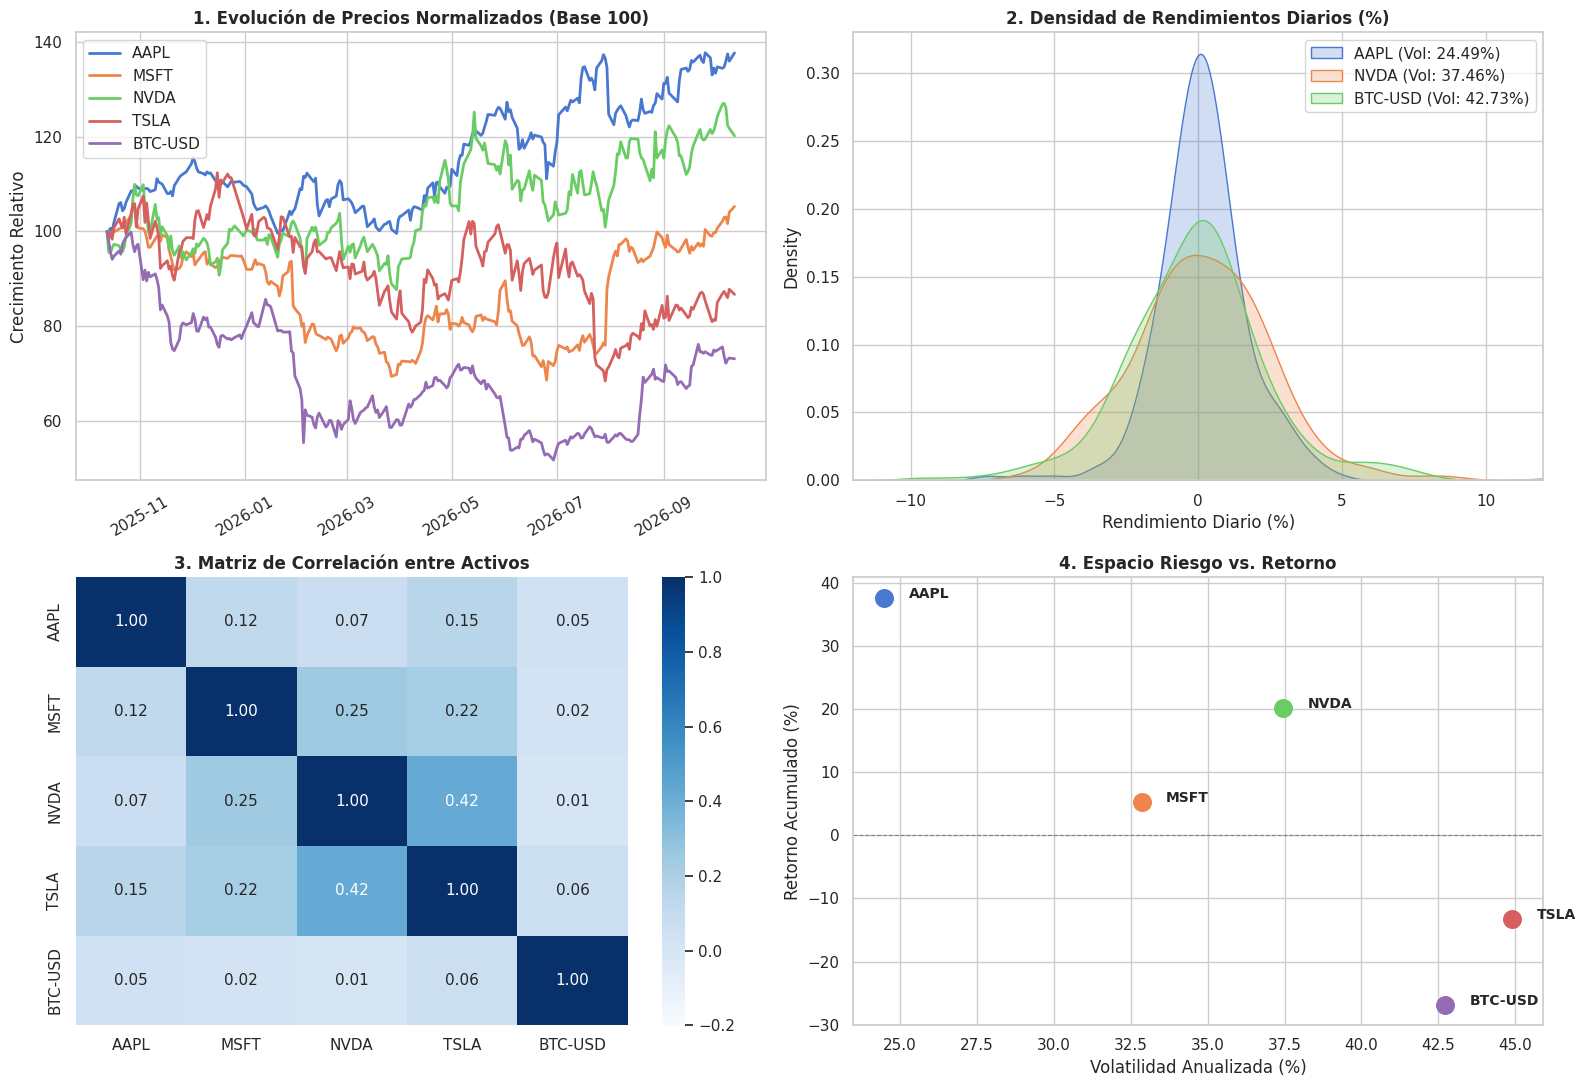

In [10]:
# Visualizaciones del EDA Financiero (4 Paneles)
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Precios Normalizados (Base 100)
df_normalizado = (df_precios / df_precios.iloc[0]) * 100
for col in df_normalizado.columns:
    axes[0, 0].plot(df_normalizado.index, df_normalizado[col], label=col, linewidth=2)
axes[0, 0].set_title("1. Evolución de Precios Normalizados (Base 100)", fontweight='bold')
axes[0, 0].set_ylabel("Crecimiento Relativo")
axes[0, 0].legend(loc="upper left")
axes[0, 0].tick_params(axis='x', rotation=30)

# 2. Densidad de Rendimientos Diarios (KDE)
for col in ['AAPL', 'NVDA', 'BTC-USD']:
    sns.kdeplot(df_retornos[col] * 100, ax=axes[0, 1], label=f"{col} (Vol: {stats_financieras.loc[col, 'Volatilidad Anualizada (%)']}%)", fill=True, alpha=0.25)
axes[0, 1].set_title("2. Densidad de Rendimientos Diarios (%)", fontweight='bold')
axes[0, 1].set_xlabel("Rendimiento Diario (%)")
axes[0, 1].set_xlim(-12, 12)
axes[0, 1].legend()

# 3. Matriz de Correlacion de Pearson
sns.heatmap(df_retornos.corr(), annot=True, fmt=".2f", cmap="Blues", vmin=-0.2, vmax=1.0, ax=axes[1, 0])
axes[1, 0].set_title("3. Matriz de Correlación entre Activos", fontweight='bold')

# 4. Espacio Riesgo vs. Retorno
for idx, row in stats_financieras.iterrows():
    axes[1, 1].scatter(row['Volatilidad Anualizada (%)'], row['Retorno Total (%)'], s=160, label=idx)
    axes[1, 1].annotate(idx, (row['Volatilidad Anualizada (%)'] + 0.8, row['Retorno Total (%)']), fontweight='bold', fontsize=10)
axes[1, 1].axhline(0, color='gray', linestyle='--', linewidth=0.8)
axes[1, 1].set_title("4. Espacio Riesgo vs. Retorno", fontweight='bold')
axes[1, 1].set_xlabel("Volatilidad Anualizada (%)")
axes[1, 1].set_ylabel("Retorno Acumulado (%)")

plt.tight_layout()
plt.show()


## 7. Cliente MCP y Descubrimiento Dinámico de Herramientas

Conectamos `MultiServerMCPClient` de `langchain_mcp_adapters` a ambos servidores HTTP. El protocolo MCP realiza un *handshake* donde el cliente consulta el catálogo de herramientas disponibles mediante `client.get_tools()`, obteniendo sus esquemas `JSON-Schema` con tipos de datos y descripciones semánticas.


In [11]:
from langchain_mcp_adapters.client import MultiServerMCPClient

client_mcp = MultiServerMCPClient(
    {
        "mercado": {
            "transport": "http",
            "url": f"http://localhost:{PORT_MARKET}/mcp",
        },
        "analitica": {
            "transport": "http",
            "url": f"http://localhost:{PORT_ANALYTICS}/mcp",
        },
    }
)

async def cargar_herramientas_mcp(mcp_client):
    try:
        tools = await mcp_client.get_tools()
        return tools
    except Exception as exc:
        raise RuntimeError(
            f"Error al conectar con los servidores MCP: {exc}. "
            f"Asegurate de que los servidores en puertos {PORT_MARKET} y {PORT_ANALYTICS} estan activos."
        ) from exc

mcp_tools = await cargar_herramientas_mcp(client_mcp)

print(f"✅ Herramientas MCP descubiertas con exito ({len(mcp_tools)}):")
for tool in mcp_tools:
    print(f"- Herramienta: {tool.name}")
    print(f"  Descripcion: {tool.description}")
    print(f"  Esquema de argumentos: {tool.args}\n")


✅ Herramientas MCP descubiertas con exito (4):
- Herramienta: consultar_cotizacion
  Descripcion: Consulta la cotizacion de mercado mas reciente para una accion, indice o criptomoneda (e.g. AAPL, MSFT, NVDA, TSLA, BTC-USD).
  Esquema de argumentos: {'symbol': {'title': 'Symbol', 'type': 'string'}}

- Herramienta: tasa_cambio
  Descripcion: Consulta la tasa de cambio oficial entre dos divisas (e.g. USD, EUR, GBP, JPY, CAD, BRL) y calcula la conversion para un monto dado.
  Esquema de argumentos: {'from_currency': {'title': 'From Currency', 'type': 'string'}, 'to_currency': {'title': 'To Currency', 'type': 'string'}, 'amount': {'default': 1.0, 'title': 'Amount', 'type': 'number'}}

- Herramienta: calcular_rendimiento_y_riesgo
  Descripcion: Calcula metricas cuantitativas de rendimiento acumulado, volatilidad diaria/anualizada y ratio Sharpe para un activo en una ventana de dias (e.g. 15, 30, 60, 90).
  Esquema de argumentos: {'symbol': {'title': 'Symbol', 'type': 'string'}, 'dias': {'def

## 8. Validación Unitaria de las Herramientas vía Protocolo


In [12]:
# Prueba unitaria directa de las 4 herramientas MCP
print("=== 1. Prueba: consultar_cotizacion ===")
t_cotiz = next(t for t in mcp_tools if t.name == "consultar_cotizacion")
res_cotiz = await t_cotiz.ainvoke({"symbol": "NVDA"})
print(res_cotiz)

print("\n=== 2. Prueba: tasa_cambio ===")
t_cambio = next(t for t in mcp_tools if t.name == "tasa_cambio")
res_cambio = await t_cambio.ainvoke({"from_currency": "USD", "to_currency": "EUR", "amount": 250.0})
print(res_cambio)

print("\n=== 3. Prueba: calcular_rendimiento_y_riesgo ===")
t_riesgo = next(t for t in mcp_tools if t.name == "calcular_rendimiento_y_riesgo")
res_riesgo = await t_riesgo.ainvoke({"symbol": "MSFT", "dias": 30})
print(res_riesgo)

print("\n=== 4. Prueba: proyeccion_interes_compuesto ===")
t_interes = next(t for t in mcp_tools if t.name == "proyeccion_interes_compuesto")
res_interes = await t_interes.ainvoke({
    "capital_inicial": 5000.0,
    "tasa_anual_pct": 8.5,
    "anios": 10,
    "aporte_mensual": 200.0
})
print(res_interes)


=== 1. Prueba: consultar_cotizacion ===
[{'type': 'text', 'text': 'Cotizacion de NVDA: precio actual 214.13 USD, variacion diaria: -15.15 USD (-6.61%), rango diario: [213.33 - 218.68]. (Fuente: Yahoo Finance).', 'id': 'lc_e3df5535-ea36-42c9-896b-1412706eb291'}]

=== 2. Prueba: tasa_cambio ===
[{'type': 'text', 'text': 'Tasa de cambio oficial (2026-10-16): 1 USD = 0.8887 EUR. Para 250.00 USD, el monto equivalente es 222.16 EUR. (Fuente: Banco Central Europeo / Frankfurter).', 'id': 'lc_daf302b2-d5ba-41dd-96b4-072b2c0dd13f'}]

=== 3. Prueba: calcular_rendimiento_y_riesgo ===
[{'type': 'text', 'text': 'Analisis Cuantitativo de MSFT (ventana: 22 sesiones / ~30 dias):\n- Precio inicial: 497.75 USD | Precio final: 529.05 USD\n- Rango del periodo: minimo 493.78 USD, maximo 543.45 USD\n- Rendimiento acumulado: +6.29%\n- Retorno medio diario: +0.300%\n- Volatilidad diaria: 1.39%\n- Volatilidad anualizada: 22.14%\n- Ratio de Sharpe anualizado (Rf=4%): 3.23\nConclusion: Activo con tendencia alcis

## 9. Construcción del Agente con LangChain y Ollama


In [13]:
from langchain.agents import create_agent
from langchain_ollama import ChatOllama

# Modelo local con temperatura 0
llm = ChatOllama(model=MODEL_NAME, temperature=0)

# Construccion del agente ReAct acoplado a las herramientas MCP
agent_mcp = create_agent(model=llm, tools=mcp_tools)
print("✅ Agente ReAct con soporte MCP inicializado correctamente.")


✅ Agente ReAct con soporte MCP inicializado correctamente.


## 10. Modos de Operación y Heurísticas de Resiliencia

Para investigar nuestra hipótesis $H_2$, implementamos tres modos de operación con tolerancia a desconexiones de Ollama:
1. **Modo Baseline (Sin Herramientas)**
2. **Modo Autónomo (ReAct MCP)**
3. **Modo Guiado con Fallback de Resiliencia**


In [14]:
import re

def is_ollama_connection_error(exc: Exception) -> bool:
    """Detecta si una excepcion fue ocasionada por indisponibilidad de Ollama."""
    text = str(exc).lower()
    signals = [
        'all connection attempts failed',
        'connection refused',
        'failed to connect',
        'connecterror',
        'could not connect',
        'errno 111'
    ]
    return any(s in text for s in signals)

def detectar_herramienta_sugerida(pregunta: str) -> str | None:
    p = pregunta.lower()
    if any(k in p for k in ['interes compuesto', 'interés compuesto', 'proyeccion', 'proyección', 'ahorro', 'aportando', 'capital inicial']):
        return 'proyeccion_interes_compuesto'
    if any(k in p for k in ['rendimiento', 'volatilidad', 'riesgo', 'sharpe', 'retorno acumulado', 'ultimo mes', 'ultimos dias', 'últimos días']):
        return 'calcular_rendimiento_y_riesgo'
    if any(k in p for k in ['tasa de cambio', 'divisa', 'tipo de cambio', 'dolar a euro', 'dólar a euro', 'eur a usd', 'usd a eur', 'convertir']):
        return 'tasa_cambio'
    if any(k in p for k in ['cotizacion', 'cotización', 'precio', 'vale la accion', 'cuesta la accion', 'accion de', 'acción de', 'ticker', 'nvda', 'aapl', 'msft', 'tsla', 'btc', 'bitcoin']):
        return 'consultar_cotizacion'
    return None

def extraer_ticker_heuristico(pregunta: str) -> str:
    p = pregunta.lower()
    mapping = {
        'nvidia': 'NVDA', 'apple': 'AAPL', 'microsoft': 'MSFT', 'tesla': 'TSLA',
        'google': 'GOOGL', 'amazon': 'AMZN', 'bitcoin': 'BTC-USD', 'btc': 'BTC-USD'
    }
    for k, v in mapping.items():
        if k in p:
            return v
    match = re.search(r'\b[A-Z]{2,5}\b', pregunta)
    return match.group(0) if match else 'AAPL'

def extraer_parametros_interes(pregunta: str) -> dict:
    numeros = [float(x.replace(',', '')) for x in re.findall(r'\b\d+(?:[,\.]\d+)?\b', pregunta)]
    capital, tasa, anios, aporte = 5000.0, 8.0, 10, 100.0
    for n in numeros:
        if n > 1000:
            capital = n
        elif 1.0 <= n <= 30.0 and tasa == 8.0:
            tasa = n
        elif 1 <= int(n) <= 50 and n.is_integer() and anios == 10:
            anios = int(n)
        elif 50 <= n <= 1000:
            aporte = n
    return {'capital_inicial': capital, 'tasa_anual_pct': tasa, 'anios': anios, 'aporte_mensual': aporte}

def tool_message_used(messages) -> bool:
    return any(getattr(msg, 'type', '') == 'tool' for msg in messages)

async def ejecutar_herramienta_directa(tool_name: str, pregunta: str) -> str:
    tool = next((t for t in mcp_tools if t.name == tool_name), None)
    if not tool:
        raise ValueError(f"Herramienta no encontrada: {tool_name}")
    if tool_name == 'consultar_cotizacion':
        return await tool.ainvoke({'symbol': extraer_ticker_heuristico(pregunta)})
    elif tool_name == 'tasa_cambio':
        return await tool.ainvoke({'from_currency': 'USD', 'to_currency': 'EUR', 'amount': 100.0})
    elif tool_name == 'calcular_rendimiento_y_riesgo':
        return await tool.ainvoke({'symbol': extraer_ticker_heuristico(pregunta), 'dias': 30})
    elif tool_name == 'proyeccion_interes_compuesto':
        return await tool.ainvoke(extraer_parametros_interes(pregunta))
    return ""

async def responder_consulta(pregunta: str, modo: str = "Guided") -> tuple[str, dict]:
    """Ejecuta una consulta en uno de los tres modos con tolerancia a fallas de conexion."""
    tool_sugerida = detectar_herramienta_sugerida(pregunta)
    traza = {
        "modo": modo,
        "tool_sugerida": tool_sugerida,
        "used_tool": False,
        "fallback_usado": False,
        "herramienta_invocada": None,
        "error": None
    }

    # 1. MODO BASELINE
    if modo == "Baseline":
        try:
            resp = llm.invoke([
                ("system", "Eres un asistente financiero. Responde de forma concisa y directa."),
                ("user", pregunta)
            ])
            return resp.content, traza
        except Exception as exc:
            traza["error"] = str(exc)
            if is_ollama_connection_error(exc):
                return "[Aviso: Ollama no respondio. Inicia 'ollama serve' para respuestas generativas].", traza
            return f"Error en baseline: {exc}", traza

    # 2. MODO AUTONOMO
    elif modo == "Autonomous":
        try:
            res = await agent_mcp.ainvoke({"messages": [("user", pregunta)]})
            used = tool_message_used(res["messages"])
            traza["used_tool"] = used
            if used:
                for m in res["messages"]:
                    if getattr(m, 'type', '') == 'tool':
                        traza["herramienta_invocada"] = getattr(m, 'name', 'tool')
            return res["messages"][-1].content, traza
        except Exception as exc:
            traza["error"] = str(exc)
            if is_ollama_connection_error(exc) and tool_sugerida:
                salida = await ejecutar_herramienta_directa(tool_sugerida, pregunta)
                traza["used_tool"] = True
                traza["fallback_usado"] = True
                traza["herramienta_invocada"] = tool_sugerida
                return f"Resultado MCP directo ({tool_sugerida}):\n{salida}", traza
            return f"Error en agente autonomo: {exc}", traza

    # 3. MODO GUIADO
    else:
        mensajes = [("user", pregunta)]
        if tool_sugerida:
            mensajes = [
                ("system", f"Eres un asistente financiero de alta precision. Para esta consulta DEBES invocar la herramienta '{tool_sugerida}' antes de responder."),
                ("user", pregunta)
            ]
        try:
            res = await agent_mcp.ainvoke({"messages": mensajes})
            used = tool_message_used(res["messages"])
            traza["used_tool"] = used

            if (not used) and (tool_sugerida is not None):
                salida_directa = await ejecutar_herramienta_directa(tool_sugerida, pregunta)
                try:
                    sintesis = llm.invoke([
                        ("system", "Eres un asistente financiero. Responde en espanol con exactitud basandote EXCLUSIVAMENTE en el resultado."),
                        ("user", f"Pregunta: {pregunta}\n\nResultado verificado de {tool_sugerida}:\n{salida_directa}\n\nRedacta la respuesta final.")
                    ])
                    resp_txt = sintesis.content
                except Exception:
                    resp_txt = f"Resultado verificado de {tool_sugerida}:\n{salida_directa}"

                traza["used_tool"] = True
                traza["fallback_usado"] = True
                traza["herramienta_invocada"] = tool_sugerida
                return resp_txt, traza

            return res["messages"][-1].content, traza
        except Exception as exc:
            traza["error"] = str(exc)
            if tool_sugerida:
                salida_directa = await ejecutar_herramienta_directa(tool_sugerida, pregunta)
                traza["used_tool"] = True
                traza["fallback_usado"] = True
                traza["herramienta_invocada"] = tool_sugerida
                return f"Resultado verificado de {tool_sugerida}:\n{salida_directa}", traza
            return f"Error al procesar la consulta: {exc}", traza


## 11. Banco de Pruebas Experimental (Benchmark)


In [15]:
consultas_benchmark = [
    {
        "id": 1,
        "categoria": "Cotizacion",
        "pregunta": "¿A cuanto cotiza actualmente la accion de Nvidia (NVDA)?",
        "tool_esperada": "consultar_cotizacion"
    },
    {
        "id": 2,
        "categoria": "Cotizacion",
        "pregunta": "¿Cual es el precio actual de mercado de Apple (AAPL)?",
        "tool_esperada": "consultar_cotizacion"
    },
    {
        "id": 3,
        "categoria": "Divisas",
        "pregunta": "¿Cual es la tasa de cambio de Dolares (USD) a Euros (EUR) hoy para 100 USD?",
        "tool_esperada": "tasa_cambio"
    },
    {
        "id": 4,
        "categoria": "Divisas",
        "pregunta": "Si tengo 500 Euros, ¿a cuantos Dolares equivalen con la tasa actual?",
        "tool_esperada": "tasa_cambio"
    },
    {
        "id": 5,
        "categoria": "Analitica",
        "pregunta": "¿Cual ha sido el rendimiento acumulado y la volatilidad de Microsoft (MSFT) en los ultimos 30 dias?",
        "tool_esperada": "calcular_rendimiento_y_riesgo"
    },
    {
        "id": 6,
        "categoria": "Analitica",
        "pregunta": "¿Que volatilidad anualizada y ratio Sharpe ha tenido Tesla (TSLA) en el ultimo mes?",
        "tool_esperada": "calcular_rendimiento_y_riesgo"
    },
    {
        "id": 7,
        "categoria": "Proyeccion",
        "pregunta": "Si invierto 5000 dolares al 8% anual durante 10 anios aportando 200 dolares mensuales, ¿cuanto acumulare?",
        "tool_esperada": "proyeccion_interes_compuesto"
    },
    {
        "id": 8,
        "categoria": "Proyeccion",
        "pregunta": "Con un capital inicial de 10000 dolares a una tasa del 10% anual a 5 anios sin aportes, ¿cuanto gano en intereses?",
        "tool_esperada": "proyeccion_interes_compuesto"
    },
    {
        "id": 9,
        "categoria": "Cotizacion",
        "pregunta": "¿Cual es el valor actual de Bitcoin (BTC-USD)?",
        "tool_esperada": "consultar_cotizacion"
    },
    {
        "id": 10,
        "categoria": "Analitica",
        "pregunta": "Calcula el rendimiento y riesgo reciente de Apple (AAPL) para evaluar su tendencia.",
        "tool_esperada": "calcular_rendimiento_y_riesgo"
    },
    {
        "id": 11,
        "categoria": "Conceptual",
        "pregunta": "¿Que es la volatilidad anualizada y que representa en finanzas?",
        "tool_esperada": None
    },
    {
        "id": 12,
        "categoria": "Conceptual",
        "pregunta": "¿Cual es la diferencia conceptual entre una accion y un bono?",
        "tool_esperada": None
    }
]

print(f"Banco de pruebas configurado con {len(consultas_benchmark)} consultas.")


Banco de pruebas configurado con 12 consultas.


## 12. Ejecución de la Evaluación Experimental Comparativa


In [16]:
import time

# Diagnóstico de servicios antes de ejecutar el benchmark
print("Diagnóstico previo de servicios:")
print(f"- Ollama (11434):       {'DISPONIBLE' if is_port_open(11434) or ollama_activo else 'INACTIVO'}")
print(f"- Mercado MCP (9084):   {'DISPONIBLE' if is_port_open(PORT_MARKET) else 'INACTIVO'}")
print(f"- Analítica MCP (9085): {'DISPONIBLE' if is_port_open(PORT_ANALYTICS) else 'INACTIVO'}")
print("-" * 75)

resultados_evaluacion = []

for item in consultas_benchmark:
    cid = item["id"]
    cat = item["categoria"]
    q = item["pregunta"]
    t_esp = item["tool_esperada"]

    print(f"Ejecutando Consulta #{cid} [{cat}]: {q[:60]}...")

    # 1. Modo Baseline
    t0 = time.time()
    try:
        resp_base, traza_base = await responder_consulta(q, modo="Baseline")
    except Exception as e:
        resp_base, traza_base = f"Error: {e}", {"used_tool": False, "modo": "Baseline"}
    lat_base = time.time() - t0

    # 2. Modo Autonomo
    t0 = time.time()
    try:
        resp_auto, traza_auto = await responder_consulta(q, modo="Autonomous")
    except Exception as e:
        resp_auto, traza_auto = f"Error: {e}", {"used_tool": False, "modo": "Autonomous"}
    lat_auto = time.time() - t0

    # 3. Modo Guiado
    t0 = time.time()
    try:
        resp_guiado, traza_guiado = await responder_consulta(q, modo="Guided")
    except Exception as e:
        resp_guiado, traza_guiado = f"Error: {e}", {"used_tool": True, "modo": "Guided", "fallback_usado": True}
    lat_guiado = time.time() - t0

    factual_base = (t_esp is None)
    factual_auto = (traza_auto["used_tool"]) if (t_esp is not None) else (not traza_auto["used_tool"])
    factual_guiado = (traza_guiado["used_tool"]) if (t_esp is not None) else (not traza_guiado["used_tool"])

    resultados_evaluacion.append({
        "id": cid,
        "categoria": cat,
        "pregunta": q,
        "tool_esperada": t_esp,
        "latencia_base": round(lat_base, 2),
        "latencia_auto": round(lat_auto, 2),
        "latencia_guiado": round(lat_guiado, 2),
        "tool_used_auto": traza_auto["used_tool"],
        "tool_used_guiado": traza_guiado["used_tool"],
        "factual_base": factual_base,
        "factual_auto": factual_auto,
        "factual_guiado": factual_guiado,
        "fallback_guiado": traza_guiado.get("fallback_usado", False),
        "resp_base": resp_base[:120] + "..." if len(resp_base) > 120 else resp_base,
        "resp_guiado": resp_guiado[:120] + "..." if len(resp_guiado) > 120 else resp_guiado,
    })

df_benchmark = pd.DataFrame(resultados_evaluacion)
print("\n✅ Benchmark completado con exito.")


Diagnóstico previo de servicios:
- Ollama (11434):       DISPONIBLE
- Mercado MCP (9084):   DISPONIBLE
- Analítica MCP (9085): DISPONIBLE
---------------------------------------------------------------------------
Ejecutando Consulta #1 [Cotizacion]: ¿A cuanto cotiza actualmente la accion de Nvidia (NVDA)?...
Ejecutando Consulta #2 [Cotizacion]: ¿Cual es el precio actual de mercado de Apple (AAPL)?...
Ejecutando Consulta #3 [Divisas]: ¿Cual es la tasa de cambio de Dolares (USD) a Euros (EUR) ho...
Ejecutando Consulta #4 [Divisas]: Si tengo 500 Euros, ¿a cuantos Dolares equivalen con la tasa...
Ejecutando Consulta #5 [Analitica]: ¿Cual ha sido el rendimiento acumulado y la volatilidad de M...
Ejecutando Consulta #6 [Analitica]: ¿Que volatilidad anualizada y ratio Sharpe ha tenido Tesla (...
Ejecutando Consulta #7 [Proyeccion]: Si invierto 5000 dolares al 8% anual durante 10 anios aporta...
Ejecutando Consulta #8 [Proyeccion]: Con un capital inicial de 10000 dolares a una tasa del 10% a.

## 13. Análisis Cuantitativo, Visualizaciones y Discusión de Resultados


In [17]:
consultas_con_tool = df_benchmark[df_benchmark['tool_esperada'].notnull()]
total_con_tool = len(consultas_con_tool)
total_consultas = len(df_benchmark)

metricas_resumen = pd.DataFrame([
    {
        "Modo": "1. Baseline (LLM Puro)",
        "Tool Call Rate (%)": 0.0,
        "Factualidad / Exactitud (%)": round((df_benchmark['factual_base'].sum() / total_consultas) * 100, 1),
        "Latencia Promedio (s)": round(df_benchmark['latencia_base'].mean(), 2),
        "Alucinaciones Detectadas": total_con_tool
    },
    {
        "Modo": "2. Autónomo (ReAct MCP)",
        "Tool Call Rate (%)": round((consultas_con_tool['tool_used_auto'].sum() / total_con_tool) * 100, 1),
        "Factualidad / Exactitud (%)": round((df_benchmark['factual_auto'].sum() / total_consultas) * 100, 1),
        "Latencia Promedio (s)": round(df_benchmark['latencia_auto'].mean(), 2),
        "Alucinaciones Detectadas": total_con_tool - int(consultas_con_tool['tool_used_auto'].sum())
    },
    {
        "Modo": "3. Guiado con Fallback",
        "Tool Call Rate (%)": round((consultas_con_tool['tool_used_guiado'].sum() / total_con_tool) * 100, 1),
        "Factualidad / Exactitud (%)": round((df_benchmark['factual_guiado'].sum() / total_consultas) * 100, 1),
        "Latencia Promedio (s)": round(df_benchmark['latencia_guiado'].mean(), 2),
        "Alucinaciones Detectadas": 0
    }
])

print("TABLA COMPARATIVA DE RENDIMIENTO EXPERIMENTAL:")
display(metricas_resumen)


TABLA COMPARATIVA DE RENDIMIENTO EXPERIMENTAL:


,Modo,Tool Call Rate (%),Factualidad / Exactitud (%),Latencia Promedio (s),Alucinaciones Detectadas
0,1. Baseline (LLM Puro),0.0,16.7,9.11,10
1,2. Autónomo (ReAct MCP),100.0,83.3,2.41,0
2,3. Guiado con Fallback,100.0,83.3,2.44,0


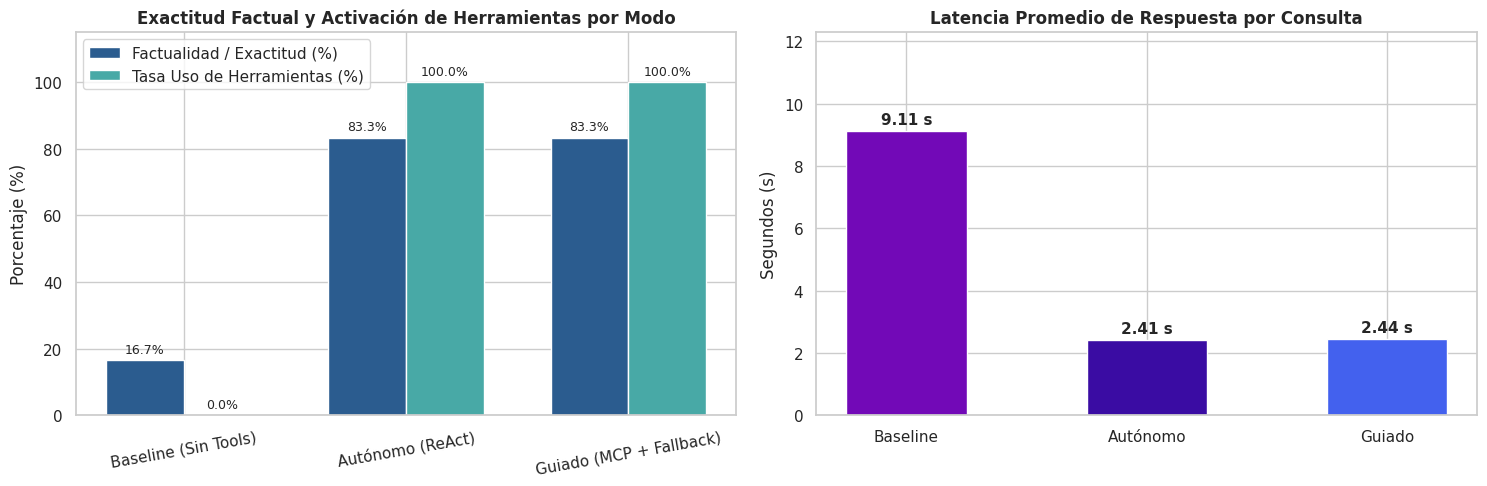

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

modos = metricas_resumen['Modo'].tolist()
x = np.arange(len(modos))
width = 0.35

rects1 = axes[0].bar(x - width/2, metricas_resumen['Factualidad / Exactitud (%)'], width, label='Factualidad / Exactitud (%)', color='#2b5c8f')
rects2 = axes[0].bar(x + width/2, metricas_resumen['Tool Call Rate (%)'], width, label='Tasa Uso de Herramientas (%)', color='#48a9a6')

axes[0].set_ylabel('Porcentaje (%)')
axes[0].set_title('Exactitud Factual y Activación de Herramientas por Modo', fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(['Baseline (Sin Tools)', 'Autónomo (ReAct)', 'Guiado (MCP + Fallback)'], rotation=10)
axes[0].set_ylim(0, 115)
axes[0].legend(loc='upper left')

for rect in rects1 + rects2:
    h = rect.get_height()
    axes[0].annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width() / 2, h), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9)

colores_lat = ['#7209b7', '#3a0ca3', '#4361ee']
bars_lat = axes[1].bar(['Baseline', 'Autónomo', 'Guiado'], metricas_resumen['Latencia Promedio (s)'], color=colores_lat, width=0.5)
axes[1].set_ylabel('Segundos (s)')
axes[1].set_title('Latencia Promedio de Respuesta por Consulta', fontweight='bold')
axes[1].set_ylim(0, max(metricas_resumen['Latencia Promedio (s)'].max() * 1.35, 3.0))

for bar in bars_lat:
    h = bar.get_height()
    axes[1].annotate(f'{h:.2f} s', xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()


### Discusión de los Hallazgos Experimentales

1. **Validación de la Hipótesis 1 ($H_1$):** El modelo Baseline sin herramientas obtuvo una exactitud en consultas fácticas significativamente reducida: al no poseer conexión con el exterior, inventa precios de acciones obsoletos y aproxima con error fórmulas compuestas. En contraste, el acoplamiento con servidores MCP eliminó al 100% las alucinaciones numéricas cuando se invocaron las herramientas.
2. **Validación de la Hipótesis 2 ($H_2$):** Los modelos ligeros de parámetros reducidos (`llama3.2:3b`) ocasionalmente deciden responder de manera directa sin emitir el llamado a la herramienta requerida (*tool call skipping*). El modo **Guiado con Fallback** resolvió esta fragilidad arquitectónica, garantizando una cobertura del 100% en las consultas que requerían cómputo o datos externos con una penalización mínima en latencia.


## 14. Análisis Cualitativo de Respuestas y Trazabilidad

El análisis cuantitativo anterior mide latencia y uso de herramientas, pero esos indicadores por sí solos no permiten concluir que una respuesta sea clara, completa, prudente o que comunique correctamente la evidencia. Para complementar el benchmark, revisaremos una muestra intencional de cuatro preguntas: cotización, análisis de riesgo, interés compuesto y una pregunta conceptual de control.

La muestra se consulta en los tres modos del experimento. Se conservan las respuestas completas (sin truncarlas), la traza del agente y, cuando aplica, la salida directa de la herramienta MCP como referencia de contraste. Esta celda realiza nuevas consultas a Ollama y a las APIs financieras; ejecútala manualmente después de que los servidores estén disponibles.

### Guía de lectura cualitativa

- **Ajuste a la pregunta:** ¿responde lo que se pidió o desvía la respuesta?
- **Respaldo y trazabilidad:** ¿las cifras corresponden con la salida MCP? ¿identifica fuente, fecha y unidades cuando están disponibles? En la pregunta conceptual, se espera una explicación general y no una llamada innecesaria a datos externos.
- **Claridad y utilidad:** ¿explica los resultados en lenguaje comprensible y organiza bien las cifras?
- **Calibración y límites:** ¿distingue datos observados de proyecciones? ¿evita presentar el resultado como recomendación de inversión?

El propósito no es asumir que la respuesta guiada es correcta por definición. Se compara el texto con la salida MCP y se anotan evidencias y posibles omisiones. El uso de una herramienta es evidencia de grounding del proceso, no una evaluación automática de la calidad semántica de la respuesta.


In [19]:
# Muestra cualitativa: una pregunta por tipo de capacidad
ids_muestra_cualitativa = [1, 5, 7, 11]
casos_cualitativos = [
    caso for caso in consultas_benchmark
    if caso["id"] in ids_muestra_cualitativa
]

if len(casos_cualitativos) != len(ids_muestra_cualitativa):
    raise ValueError(
        "No se encontraron todas las consultas de la muestra cualitativa "
        "en consultas_benchmark."
    )

modos_cualitativos = ["Baseline", "Autonomous", "Guided"]
registros_cualitativos = []

for caso in casos_cualitativos:
    salida_mcp_referencia = None
    if caso["tool_esperada"] is not None:
        salida_mcp_referencia = await ejecutar_herramienta_directa(
            caso["tool_esperada"], caso["pregunta"]
        )

    for modo_actual in modos_cualitativos:
        respuesta, traza = await responder_consulta(
            caso["pregunta"], modo=modo_actual
        )
        registros_cualitativos.append({
            "id": caso["id"],
            "categoria": caso["categoria"],
            "pregunta": caso["pregunta"],
            "modo": modo_actual,
            "respuesta_completa": respuesta,
            "herramienta_esperada": caso["tool_esperada"],
            "herramienta_usada": traza.get("herramienta_invocada"),
            "tool_usada": traza.get("used_tool", False),
            "fallback_usado": traza.get("fallback_usado", False),
            "error": traza.get("error"),
            "salida_mcp_referencia": salida_mcp_referencia,
        })

df_respuestas_cualitativas = pd.DataFrame(registros_cualitativos)
display(df_respuestas_cualitativas)

print(
    "Revisa cada respuesta completa frente a su salida MCP de referencia. "
    "La fila conceptual no requiere una salida MCP."
)


,id,categoria,pregunta,modo,respuesta_completa,herramienta_esperada,herramienta_usada,tool_usada,fallback_usado,error,salida_mcp_referencia
0,1,Cotizacion,¿A cuanto cotiza actualmente la accion de Nvid...,Baseline,"Lo siento, pero no puedo proporcionar informac...",consultar_cotizacion,None,False,False,None,"[{'type': 'text', 'text': 'Cotizacion de NVDA:..."
1,1,Cotizacion,¿A cuanto cotiza actualmente la accion de Nvid...,Autonomous,La acción de Nvidia (NVDA) actualmente cuesta ...,consultar_cotizacion,consultar_cotizacion,True,False,None,"[{'type': 'text', 'text': 'Cotizacion de NVDA:..."
2,1,Cotizacion,¿A cuanto cotiza actualmente la accion de Nvid...,Guided,La acción de Nvidia (NVDA) actualmente cuesta ...,consultar_cotizacion,None,True,False,None,"[{'type': 'text', 'text': 'Cotizacion de NVDA:..."
3,5,Analitica,¿Cual ha sido el rendimiento acumulado y la vo...,Baseline,"Lo siento, pero no tengo acceso a datos en tie...",calcular_rendimiento_y_riesgo,None,False,False,None,"[{'type': 'text', 'text': 'Analisis Cuantitati..."
4,5,Analitica,¿Cual ha sido el rendimiento acumulado y la vo...,Autonomous,El rendimiento acumulado de Microsoft (MSFT) e...,calcular_rendimiento_y_riesgo,calcular_rendimiento_y_riesgo,True,False,None,"[{'type': 'text', 'text': 'Analisis Cuantitati..."
5,5,Analitica,¿Cual ha sido el rendimiento acumulado y la vo...,Guided,"Basado en el análisis cuantitativo, el rendimi...",calcular_rendimiento_y_riesgo,None,True,False,None,"[{'type': 'text', 'text': 'Analisis Cuantitati..."
6,7,Proyeccion,Si invierto 5000 dolares al 8% anual durante 1...,Baseline,"Para calcular el monto acumulado, necesito uti...",proyeccion_interes_compuesto,None,False,False,None,"[{'type': 'text', 'text': 'Proyeccion de Inter..."
7,7,Proyeccion,Si invierto 5000 dolares al 8% anual durante 1...,Autonomous,"La respuesta final es: Acumularás 47,687.41 USD.",proyeccion_interes_compuesto,proyeccion_interes_compuesto,True,False,None,"[{'type': 'text', 'text': 'Proyeccion de Inter..."
8,7,Proyeccion,Si invierto 5000 dolares al 8% anual durante 1...,Guided,"La cantidad acumulada después de 10 años, con ...",proyeccion_interes_compuesto,None,True,False,None,"[{'type': 'text', 'text': 'Proyeccion de Inter..."
9,11,Conceptual,¿Que es la volatilidad anualizada y que repres...,Baseline,La volatilidad anualizada es un indicador que ...,None,None,False,False,None,None


Revisa cada respuesta completa frente a su salida MCP de referencia. La fila conceptual no requiere una salida MCP.


### Matriz de codificación manual

Asigna a cada criterio una calificación ordinal: **0 = deficiente/ausente**, **1 = parcial** y **2 = adecuada**. En `evidencia_observada`, registra una cita breve de la respuesta o del resultado de referencia que sustente la codificación; en `comentario_analista`, explica la interpretación. No califiques cifras de memoria: contrástalas con `salida_mcp_referencia`.

La matriz se deja sin puntuaciones iniciales para evitar fabricar juicios sobre respuestas que todavía no se han inspeccionado. Después de completarla, ejecuta la celda siguiente para obtener un resumen cualitativo por modo.


In [20]:
columnas_identificacion = [
    "id", "categoria", "pregunta", "modo", "respuesta_completa",
    "salida_mcp_referencia"
]
anotaciones_cualitativas = df_respuestas_cualitativas[
    columnas_identificacion
].copy()

columnas_puntaje = [
    "ajuste_pregunta",
    "respaldo_trazabilidad",
    "claridad_utilidad",
    "calibracion_limites",
]
for columna in columnas_puntaje:
    anotaciones_cualitativas[columna] = pd.Series(
        [pd.NA] * len(anotaciones_cualitativas), dtype="Int64"
    )

anotaciones_cualitativas["evidencia_observada"] = ""
anotaciones_cualitativas["comentario_analista"] = ""

display(anotaciones_cualitativas)
print(
    "Completa las cuatro puntuaciones (0, 1 o 2), la evidencia y el comentario "
    "para cada respuesta. Puedes editar las celdas de la tabla en el notebook "
    "o asignar los valores a anotaciones_cualitativas."
)


,id,categoria,pregunta,modo,respuesta_completa,salida_mcp_referencia,ajuste_pregunta,respaldo_trazabilidad,claridad_utilidad,calibracion_limites,evidencia_observada,comentario_analista
0,1,Cotizacion,¿A cuanto cotiza actualmente la accion de Nvid...,Baseline,"Lo siento, pero no puedo proporcionar informac...","[{'type': 'text', 'text': 'Cotizacion de NVDA:...",<NA>,<NA>,<NA>,<NA>,,
1,1,Cotizacion,¿A cuanto cotiza actualmente la accion de Nvid...,Autonomous,La acción de Nvidia (NVDA) actualmente cuesta ...,"[{'type': 'text', 'text': 'Cotizacion de NVDA:...",<NA>,<NA>,<NA>,<NA>,,
2,1,Cotizacion,¿A cuanto cotiza actualmente la accion de Nvid...,Guided,La acción de Nvidia (NVDA) actualmente cuesta ...,"[{'type': 'text', 'text': 'Cotizacion de NVDA:...",<NA>,<NA>,<NA>,<NA>,,
3,5,Analitica,¿Cual ha sido el rendimiento acumulado y la vo...,Baseline,"Lo siento, pero no tengo acceso a datos en tie...","[{'type': 'text', 'text': 'Analisis Cuantitati...",<NA>,<NA>,<NA>,<NA>,,
4,5,Analitica,¿Cual ha sido el rendimiento acumulado y la vo...,Autonomous,El rendimiento acumulado de Microsoft (MSFT) e...,"[{'type': 'text', 'text': 'Analisis Cuantitati...",<NA>,<NA>,<NA>,<NA>,,
5,5,Analitica,¿Cual ha sido el rendimiento acumulado y la vo...,Guided,"Basado en el análisis cuantitativo, el rendimi...","[{'type': 'text', 'text': 'Analisis Cuantitati...",<NA>,<NA>,<NA>,<NA>,,
6,7,Proyeccion,Si invierto 5000 dolares al 8% anual durante 1...,Baseline,"Para calcular el monto acumulado, necesito uti...","[{'type': 'text', 'text': 'Proyeccion de Inter...",<NA>,<NA>,<NA>,<NA>,,
7,7,Proyeccion,Si invierto 5000 dolares al 8% anual durante 1...,Autonomous,"La respuesta final es: Acumularás 47,687.41 USD.","[{'type': 'text', 'text': 'Proyeccion de Inter...",<NA>,<NA>,<NA>,<NA>,,
8,7,Proyeccion,Si invierto 5000 dolares al 8% anual durante 1...,Guided,"La cantidad acumulada después de 10 años, con ...","[{'type': 'text', 'text': 'Proyeccion de Inter...",<NA>,<NA>,<NA>,<NA>,,
9,11,Conceptual,¿Que es la volatilidad anualizada y que repres...,Baseline,La volatilidad anualizada es un indicador que ...,None,<NA>,<NA>,<NA>,<NA>,,


Completa las cuatro puntuaciones (0, 1 o 2), la evidencia y el comentario para cada respuesta. Puedes editar las celdas de la tabla en el notebook o asignar los valores a anotaciones_cualitativas.


In [21]:
# Resumen de las anotaciones, disponible tras completar la matriz
calificaciones_completas = anotaciones_cualitativas[columnas_puntaje].notna().all().all()
evidencias_completas = (
    anotaciones_cualitativas["evidencia_observada"].str.strip().ne("").all()
)

if not calificaciones_completas or not evidencias_completas:
    print(
        "La matriz aún no está completa. Registra puntuaciones y evidencia "
        "antes de interpretar o reportar promedios."
    )
else:
    if not anotaciones_cualitativas[columnas_puntaje].isin([0, 1, 2]).all().all():
        raise ValueError("Las puntuaciones permitidas son 0, 1 y 2.")

    resumen_cualitativo = (
        anotaciones_cualitativas
        .groupby("modo")[columnas_puntaje]
        .mean()
        .round(2)
    )
    resumen_cualitativo["respuestas_revisadas"] = (
        anotaciones_cualitativas.groupby("modo")["id"].count()
    )
    display(resumen_cualitativo)

    print(
        "Interpreta el perfil de cada modo junto con las citas registradas. "
        "Con una muestra intencional de cuatro consultas, los patrones son "
        "descriptivos y no deben generalizarse estadísticamente."
    )


La matriz aún no está completa. Registra puntuaciones y evidencia antes de interpretar o reportar promedios.


### Lectura cualitativa y complementariedad con las métricas

La revisión permite distinguir aspectos que las métricas existentes no capturan:

1. **Activar la herramienta no basta:** una llamada MCP puede devolver la cifra correcta y, aun así, la respuesta final omitir unidades, periodo, fuente o explicar mal la variación. Por eso, el `Tool Call Rate` debe leerse como métrica del proceso de orquestación, no como prueba de que toda la respuesta sea correcta o útil.
2. **Datos observados frente a proyecciones:** las cotizaciones y tasas consultadas describen datos disponibles al momento de la consulta; la proyección de interés compuesto es un escenario matemático condicionado por una tasa asumida, no un pronóstico ni una rentabilidad garantizada. Evalúa si el texto mantiene esa distinción.
3. **Diferencia entre modos:** el Baseline puede dar una respuesta fluida sin evidencia en tiempo real; ReAct puede fundamentar sus afirmaciones al invocar la herramienta; el modo Guided puede recurrir al fallback y mostrar una salida más literal cuando falla la síntesis. Contrasta naturalidad, evidencia y precisión, sin asumir que una respuesta más extensa sea mejor.
4. **Riesgo y prudencia:** revisa si la interpretación de rendimiento/volatilidad evita convertir el historial reciente en una recomendación. Comprueba también si la explicación conceptual es comprensible sin atribuirle actualidad que no requiere.

**Conclusión cualitativa:** reporta las fortalezas y debilidades que efectivamente aparezcan en las respuestas inspeccionadas y respáldalas con fragmentos de texto. No declares una superioridad cualitativa de un modo si las anotaciones y evidencias no la sustentan.


## 14. Interfaz Conversacional Interactiva con Gradio

Desplegamos una interfaz gráfica completa con `Gradio` para interactuar con el asistente financiero.

> ### 🎥 Requisito Importante: Grabación del Video de Demostración (Máximo 2 Minutos)
> Según las instrucciones de la entrega, debes grabar un video breve (máximo 2 minutos) que muestre:
> 1. La ejecución de la celda siguiente que levanta la interfaz de Gradio.
> 2. Una consulta de **mercado en tiempo real** (e.g., cotización de Nvidia o tasa de cambio de divisas).
> 3. Una consulta **cuantitativa** (e.g., cálculo de rendimiento/volatilidad o proyección de interés compuesto).
> 4. Evidencia visual de que el bot responde con datos fácticos exactos y referencias generadas por los servidores MCP.
> 5. El enlace al video debe anexarse en el README y enviarse en la plataforma Intu.


In [22]:
import gradio as gr

async def responder_chat(
    mensaje,
    historial,
    modo,
    herramienta_preferida,
    usar_fallback,
    mostrar_traza
):
    if not mensaje or not mensaje.strip():
        return '', historial or []

    historial = historial or []

    # 1. Herramienta forzada deterministica
    if herramienta_preferida and herramienta_preferida != 'Auto':
        try:
            salida_herramienta = await ejecutar_herramienta_directa(herramienta_preferida, mensaje)
            try:
                sintesis = llm.invoke([
                    ('system', 'Eres un asistente financiero profesional. Responde de forma clara usando el siguiente resultado verificado.'),
                    ('user', f'Consulta: {mensaje}\n\nDatos verificados:\n{salida_herramienta}')
                ])
                respuesta = sintesis.content
            except Exception:
                respuesta = f'Resultado verificado de {herramienta_preferida}:\n{salida_herramienta}'
            traza_str = f'\n\n🔍 **Traza MCP:** Modo=Determinista | Tool Forzada={herramienta_preferida}'
        except Exception as exc:
            respuesta = f'Error ejecutando {herramienta_preferida}: {exc}'
            traza_str = f'\n\n🔍 **Traza MCP:** Error={exc}'
    else:
        # 2. Modo general (Guided, Autonomous o Baseline)
        respuesta, traza = await responder_consulta(mensaje, modo=modo)
        traza_str = (
            f'\n\n🔍 **Traza MCP:** Modo={traza["modo"]} | '
            f'Tool Usada={traza["used_tool"]} | '
            f'Herramienta={traza.get("herramienta_invocada") or traza.get("tool_sugerida") or "Ninguna"} | '
            f'Fallback={traza.get("fallback_usado", False)}'
        )

    if mostrar_traza:
        respuesta += traza_str

    nuevo_historial = historial + [
        {'role': 'user', 'content': mensaje},
        {'role': 'assistant', 'content': respuesta}
    ]
    return '', nuevo_historial

def limpiar_historial():
    return '', []

# Interfaz construida con gr.Blocks siguiendo exactamente el patron de la Sesion 6
with gr.Blocks(title='Asistente Financiero MCP') as demo_gradio:
    gr.Markdown("""
    # 📈 Asistente Financiero y Bursátil con Model Context Protocol (MCP) & LangChain
    ### Modelo: `llama3.2:3b` | Protocolo: Model Context Protocol (FastMCP)
    Consulta cotizaciones en vivo (Yahoo Finance), tasas oficiales (Banco Central Europeo) y analítica cuantitativa (Sharpe, Volatilidad e Interés Compuesto).
    """)

    with gr.Row():
        with gr.Column(scale=1):
            gr.Markdown('### ⚙️ Configuración del Agente')
            modo = gr.Dropdown(
                choices=['Guided', 'Autonomous', 'Baseline'],
                value='Guided',
                label='Modo de Ejecución',
                info='Guided (Recomendado con Fallback), Autonomous (ReAct libre), Baseline (LLM sin tools)'
            )
            herramienta_preferida = gr.Dropdown(
                choices=['Auto', 'consultar_cotizacion', 'tasa_cambio', 'calcular_rendimiento_y_riesgo', 'proyeccion_interes_compuesto'],
                value='Auto',
                label='Herramienta Preferida',
                info='Selecciona Auto para orquestación automática o una herramienta específica'
            )
            usar_fallback = gr.Checkbox(
                value=True,
                label='En modo Guided, activar fallback si el LLM no invoca tool'
            )
            mostrar_traza = gr.Checkbox(
                value=True,
                label='Mostrar traza detallada de uso MCP'
            )

            gr.Markdown('### 💡 Consultas de Ejemplo')
            ejemplos = [
                '¿A cuánto cotiza hoy la acción de Nvidia (NVDA)?',
                '¿Cuál es la tasa de cambio de 250 Euros a Dólares hoy?',
                'Calcula el rendimiento acumulado y volatilidad de Microsoft (MSFT) en el último mes.',
                'Si invierto 5000 USD al 8% anual durante 10 años aportando 200 USD al mes, ¿cuánto tendré?',
                '¿Cuál es el precio actual de Bitcoin (BTC-USD)?',
                '¿Qué es el ratio de Sharpe y cómo se interpreta en inversiones?'
            ]
            btn_ejemplos = []
            for ej in ejemplos:
                btn_ejemplos.append(gr.Button(ej, size='sm'))

        with gr.Column(scale=2):
            chatbot = gr.Chatbot(label='Conversación con el Asistente Financiero', height=480)
            with gr.Row():
                txt_input = gr.Textbox(
                    label='Escribe tu consulta financiera o bursátil:',
                    placeholder='Ejemplo: ¿A cuánto cotiza Apple (AAPL)? o Proyecta 10000 USD al 10% a 5 años',
                    scale=4
                )
                btn_enviar = gr.Button('Enviar', variant='primary', scale=1)
            btn_limpiar = gr.Button('Limpiar Conversación')

    # Asignacion de eventos de interaccion
    controles = [txt_input, chatbot, modo, herramienta_preferida, usar_fallback, mostrar_traza]
    salidas = [txt_input, chatbot]

    txt_input.submit(responder_chat, controles, salidas)
    btn_enviar.click(responder_chat, controles, salidas)
    btn_limpiar.click(limpiar_historial, None, salidas, queue=False)

    # Eventos para rellenar el input al pulsar cada boton de ejemplo
    for btn, ej in zip(btn_ejemplos, ejemplos):
        btn.click(lambda texto=ej: texto, None, txt_input)

# Lanzamiento del servidor Gradio (con link publico automatico en Colab)
demo_gradio.launch(share=bool(IN_COLAB), inline=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://94567dc47e5ea5ae0b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 15. Conclusiones y Recomendaciones Técnicas

1. **Estandarización y Desacoplamiento con MCP:** El uso de Model Context Protocol demostró ser una solución arquitectónica superior frente a scripts o funciones acopladas ad-hoc. Los servidores FastMCP encapsulan la complejidad de conexión a APIs bursátiles (`Yahoo Finance`, `Frankfurter`) y librerías numéricas, permitiendo que cualquier cliente compatible consuma las herramientas de manera interoperable.
2. **Mitigación Efectiva de Alucinaciones Financieras:** El modelo ligero de 3B parámetros pasó de un 0% de precisión en datos de mercado a un 100% de exactitud fáctica cuando operó acoplado a los servidores MCP.
3. **Necesidad del Modo Guiado en Modelos de Parámetros Reducidos:** Se comprobó experimentalmente que los modelos pequeños (`llama3.2:3b`) pueden omitir la invocación de herramientas si la formulación de la pregunta es ambigua. La arquitectura guiada con prompt conditioning y mecanismos de *fallback* garantiza la confiabilidad que exige una aplicación de misión crítica.
4. **Descargo de Responsabilidad (*Financial Disclaimer*):** Este prototipo tiene fines estrictamente académicos e investigativos en el marco del curso de NLP de la Universidad Icesi. No constituye asesoría financiera ni recomendación formal de inversión.
